# B4. PURPLE 결과 파일 읽기

**목표**
- PURPLE 이 쓰는 파일 다섯 개가 각각 무엇을 담는지, 그림으로 위치를 잡고 이해합니다.
- 가짜 시료 두 개(깨끗한 것, B3 에서 뒤집힌 것)를 PURPLE 형식으로 써 보고, 실제 결과를 읽듯이 다시 읽습니다.
- B3 의 "실제 결과에서 볼 것"을 함수 하나로 만들어 시료마다 돌립니다.
- (선택) 내 PURPLE 결과 폴더에 같은 확인을 돌립니다.

**이 노트북이 답하는 질문**: 내 PURPLE 결과에서 "purity 가 낮아 CN 이 흔들린 시료"를 어떻게 골라내나?

`[번호]` 는 맨 아래 **출처** 절의 번호입니다.

In [1]:
# 그림 도구 (펼치지 않아도 됩니다). 공통 스타일 STYLE.md §3-1, 팔레트 Okabe-Ito(색의 뜻 고정)
import glob
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import purple_mini as pm

# ---- 공통 그림 스타일 (study_build/purple/_proto_pileup.py 에서 복사, STYLE.md §3-1) ----
# 색은 뜻이 고정: 종양 주황, 정상 하늘, allele A 파랑, allele B 빨강, read 회청, 핵심 메시지 자주, 정답·통과 초록.
# 그 밖의 비교(조건 둘, purity 여러 개)는 진한 회색 계열(GREYS)과 선 모양으로 구분하고 직접 라벨을 단다.
import logging
from matplotlib.patches import FancyBboxPatch

COL = dict(tumour="#E69F00", normal="#56B4E9", alleleA="#0072B2", alleleB="#D55E00",
           read="#8C9BAB", read_rev="#B3BFCC", highlight="#CC79A7", ok="#009E73",
           ink="#222222", muted="#6B7280", grid="#E5E7EB", shade="#FFF4E0")
GREYS = ["#111827", "#4B5563", "#8B95A3", "#BCC3CC"]      # 순서 있는 비교용(진한 것 = 첫째)
TUMOUR_LIGHT, NORMAL_LIGHT, BOX = "#FBE3B6", "#CDE8F8", "#F1F3F6"
NEUTRAL = "#E6E9EE"                                      # 종양과 상관없는 강조 띠·상자 (옅은 주황 shade 는 종양 구간에만)
LABEL_BOX = dict(fc="white", ec="none", alpha=0.85, pad=1.5)   # 선이나 점 위에 놓이는 글자 뒤 흰 상자


def apply_theme():
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # 글꼴 대체 경고 숨김
    plt.rcParams.update({
        "font.family": ["Arial", "DejaVu Sans"], "font.size": 10.5,
        "axes.titlesize": 11.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
        "axes.titlepad": 10, "axes.labelsize": 10.5, "axes.labelcolor": COL["ink"],
        "axes.edgecolor": "#9CA3AF", "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": False, "grid.color": COL["grid"], "grid.linewidth": 0.8,
        "xtick.color": COL["muted"], "ytick.color": COL["muted"],
        "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
        "legend.frameon": False, "legend.fontsize": 9.5,
        "figure.dpi": 110, "savefig.bbox": "tight", "figure.facecolor": "white",
    })


def panel(ax, letter, title):
    """왼쪽 정렬 'A   제목' 형식의 패널 제목"""
    ax.set_title(f"{letter}   {title}" if letter else title)


def note(ax, x, y, text, **kw):
    """회색 작은 주석"""
    kw.setdefault("fontsize", 9); kw.setdefault("color", COL["muted"])
    ax.text(x, y, text, **kw)


def callout(ax, x, y, text, **kw):
    """그림의 핵심 메시지 한 줄(자주색 굵게). 데이터 위에 겹치지 않는 빈 자리에 둔다."""
    kw.setdefault("fontsize", 10); kw.setdefault("color", COL["highlight"]); kw.setdefault("fontweight", "semibold")
    ax.text(x, y, text, **kw)


def ygrid(ax):
    ax.yaxis.grid(True); ax.set_axisbelow(True)


apply_theme()


def _box(ax, x, y, text, col, W=3.0, H=1.0, fs=9.5):
    ax.add_patch(FancyBboxPatch((x - W / 2, y - H / 2), W, H, boxstyle="round,pad=0.04,rounding_size=0.18",
                                fc=col, ec="#C4CAD3", lw=0.9, zorder=2))
    ax.text(x, y, text, ha="center", va="center", fontsize=fs, color=COL["ink"], zorder=3)


def _arrow(ax, a, b):
    ax.annotate("", xy=b, xytext=a, zorder=1,
                arrowprops=dict(arrowstyle="-|>", lw=1.0, color=COL["muted"], shrinkA=2, shrinkB=2, mutation_scale=11))


def draw_concept_map():
    fig, ax = plt.subplots(figsize=(12.5, 5.2))
    _box(ax, 1.7, 2.4, "PURPLE run\n(B2 fit + B3 smoothing)", NEUTRAL, W=3.0, H=1.2)
    files = [("purity.tsv", "final purity, ploidy,\ncandidate range", "Is the answer certain?"),
             ("purity.range.tsv", "every (purity, ploidy)\nguess and its score", "Is there a second valley?"),
             ("segment.tsv", "segments BEFORE smoothing:\nratio, BAF, penalties", "What went into the fit?"),
             ("cnv.somatic.tsv", "segments AFTER smoothing:\nCN, major, minor, support", "Final CN map; which ends\nhave SV support?"),
             ("qc", "QC status and counts\n(unsupported segments, depth)", "Any warnings? Why?")]
    for i, (name, what, q) in enumerate(files):
        y = 4.6 - i * 1.1
        _box(ax, 5.9, y, f"<sample>.purple.{name}", BOX, W=3.3, H=0.8)
        ax.text(7.8, y, what, va="center", fontsize=9.5, color=COL["ink"])
        ax.text(11.2, y, q, va="center", fontsize=9.5, color=COL["ink"], fontweight="semibold")
        _arrow(ax, (3.2, 2.4), (4.25, y))
    note(ax, 7.8, 5.35, "what is inside", fontsize=10.5, color=COL["muted"], weight="semibold")
    note(ax, 11.2, 5.35, "question it answers", fontsize=10.5, color=COL["muted"], weight="semibold")
    callout(ax, 0.2, 5.95, "Five output files, each answers one question", va="bottom")
    ax.set_xlim(0, 14.4); ax.set_ylim(-0.6, 6.3); ax.set_axis_off()
    plt.show()


def draw_support_track():
    fig, ax = plt.subplots(figsize=(12, 3.8))
    # 장난감 염색체 0~100 Mb: 동원체 45, SV 끊김 20 (BND), 60 과 70 (DEL), PCF 만의 끊김 30, 33, 80
    edges = [(0, "TELOMERE"), (20, "BND"), (30, "NONE"), (33, "NONE"), (45, "CENTROMERE"), (60, "DEL"), (70, "DEL"), (80, "NONE"), (100, "TELOMERE")]
    cns = [2, 3, 2.4, 3, 2, 1, 2, 2.3]
    for (s, ss), (e, es), c in zip(edges[:-1], edges[1:], cns):
        both_none = ss == "NONE" and es == "NONE"
        ax.plot([s + 0.2, e - 0.2], [c, c], color=COL["highlight"] if both_none else COL["ink"], lw=5, solid_capstyle="butt")
    for x, lab in edges:
        none = lab == "NONE"
        col = COL["highlight"] if none else COL["ink"]
        ax.axvline(x, color=col, lw=0.9, ls=":" if none else "-")
        ax.text(x, 3.75, lab, rotation=90, ha="center", va="bottom", fontsize=9, color=col,
                bbox=dict(facecolor="white", edgecolor="none", pad=0.6))
    callout(ax, 31.5, 1.05, "NONE on both ends\n= unsupported segment", ha="center", va="center", fontsize=9.5, bbox=LABEL_BOX)
    ax.set_xlim(-2, 102); ax.set_ylim(0.5, 5.6); ax.set_xlabel("toy chromosome (Mb)"); ax.set_ylabel("copy number"); ygrid(ax)
    panel(ax, "", "Each segment end has a 'support' (SV type, centromere, telomere, or NONE)")
    plt.show()


def draw_qc_flow():
    fig, ax = plt.subplots(figsize=(12.5, 3.4))
    _box(ax, 1.6, 1.5, "purple.qc", BOX, W=2.4)
    _box(ax, 5.4, 2.4, "UnsupportedCopyNumberSegments\n> 220 ?", "white", W=3.6)
    _box(ax, 5.4, 0.6, "purity < 0.2 ?", "white", W=3.6)
    _box(ax, 10.2, 2.4, "WARN_HIGH_COPY_NUMBER_NOISE", NEUTRAL, W=4.0)
    _box(ax, 10.2, 0.6, "WARN_LOW_PURITY", NEUTRAL, W=4.0)
    for y in (2.4, 0.6):
        _arrow(ax, (2.8, 1.5), (3.6, y)); _arrow(ax, (7.2, y), (8.2, y))
        note(ax, 7.7, y + 0.15, "yes", ha="center", color=COL["ink"])
    note(ax, 12.45, 1.5, "none of the checks\n(including others such as\nWARN_DELETED_GENES)\n-> PASS", va="center", color=COL["ink"], fontsize=9.5)
    callout(ax, 0.4, 3.25, "Two of the QC checks in this notebook: noise and low purity", va="top")
    ax.set_xlim(0, 14.8); ax.set_ylim(0, 3.35); ax.set_axis_off()
    plt.show()

## 개념 지도: 다섯 파일과 각자의 질문

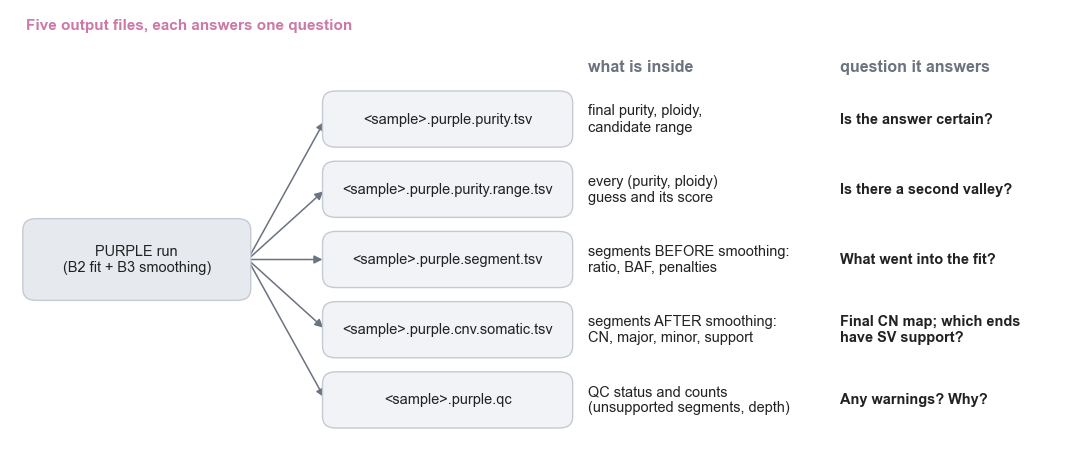

In [2]:
draw_concept_map()

## 1. 파일 다섯 개

열 이름은 PURPLE 4.1 소스(`hmf-common/.../purple/` 의 `PurityContextFile.java`, `PurpleQCFile.java`, `FittedPurityRangeFile.java` 등)와 설명서의 Output 절에서 확인했습니다 [1][2].

| 파일 | 한 줄 = | 이 노트북에서 쓰는 열 | 답하는 질문 |
|---|---|---|---|
| `<시료>.purple.purity.tsv` | 시료 하나 | `purity`, `ploidy`, `normFactor`, `score`, `minPurity`, `maxPurity`, `minPloidy`, `maxPloidy`, `diploidProportion`, `status`, `polyclonalProportion`, `wholeGenomeDuplication` | 최종 답과 그 불확실 범위 |
| `<시료>.purple.purity.range.tsv` | 추측 하나 (점수 순) | `purity`, `normFactor`, `score`, `diploidProportion`, `ploidy` | 두 번째 골짜기가 있나 |
| `<시료>.purple.segment.tsv` | 다듬기 **전** 구간 | `observedTumorRatio`, `observedBAF`, `bafCount`, `tumorCopyNumber`, `deviationPenalty`, `eventPenalty`, `support` | 맞추기에 들어간 원재료 |
| `<시료>.purple.cnv.somatic.tsv` | 다듬은 **뒤** 구간 | `copyNumber`, `minorAlleleCopyNumber`, `majorAlleleCopyNumber`, `bafCount`, `segmentStartSupport`, `segmentEndSupport` | 최종 CN 지도 |
| `<시료>.purple.qc` | `이름<탭>값` 줄 | `QCStatus`, `Method`, `CopyNumberSegments`, `UnsupportedCopyNumberSegments`, `Purity`, `AmberMeanDepth` | QC 경고와 근거 |

설명서와 코드가 다르게 말하는 곳이 두 군데 있어 코드를 따랐습니다.
- `purity.tsv` 의 `status`: 설명서 표는 QC 상태라고 적지만 [1], 4.1 코드는 **맞추기 방식**(`NORMAL`, `HIGHLY_DIPLOID`, `SOMATIC`, `NO_TUMOR`)을 씁니다(`PurityContextFile.java` 가 `method()` 를 씀 [2]). QC 상태는 `qc` 파일의 `QCStatus` 에 있습니다.
- `purity.range.tsv`: 설명서는 "purity 마다 가장 좋은 해를 점수 순으로 요약"이라고 적지만 [1], 4.1 코드는 격자의 **모든 추측**을 점수 순으로 씁니다(`PurpleApplication` 이 `bestFit.AllFits` 를 씀 [2]). 읽을 때 purity 마다 최저 점수 하나만 고르면 어느 쪽이든 같습니다.

그 밖의 열:
- `polyclonalProportion`: CN 이 정수에서 0.25 넘게 벗어난 구간의 비율 [1].
- `diploidProportion`: major·minor 가 모두 1 ± 0.2 인 구간의 비율 [1].
- `wholeGenomeDuplication`: 평균 major CN 이 1.5 이상인 상염색체가 11 개 이상이면 참 (`WholeGenomeDuplication.java` [2]; 설명서는 "1.5 초과인 상염색체가 10 개 넘게"로 적음 [1]).

### 구간 끝의 근거(support)와 근거 없는 구간

**한 줄 정의**: `cnv.somatic.tsv` 의 `segmentStartSupport`·`segmentEndSupport` 는 그 구간의 시작·끝 경계를 무엇이 받쳐 주는지 적은 것입니다 [1].
값은 `TELOMERE`, `CENTROMERE`(염색체 끝·가운데), `BND`(전좌: 다른 염색체와 이어짐), `DEL`(결실: 한 토막이 빠짐), `DUP`(중복: 한 토막이 한 번 더 붙음), `INV`(역위: 한 토막이 뒤집혀 붙음), `SGL`(한쪽 끝만 찾은 SV), `MULT`(같은 자리에 SV 여럿), 그리고 **`NONE`(SV 근거 없음)** 입니다.

**왜 중요한가**: SV 가 받치는 경계는 진짜 CN 변화일 가능성이 높습니다. 양쪽 끝이 모두 `NONE` 인 구간은 깊이 비·BAF 의 PCF 만으로 생긴 구간이라, B3 원인 3 처럼 잡음 물결일 수 있습니다.
PURPLE 은 이런 구간 수를 `qc` 파일의 `UnsupportedCopyNumberSegments` 로 셉니다 [1].

**숫자로 따라가기**: 아래 장난감 염색체에는 구간이 8 개 있습니다. 양쪽 끝이 모두 `NONE` 인 것은 30~33 Mb 구간 하나뿐입니다.
33~45 Mb 구간은 한쪽 끝이 `CENTROMERE`, 70~80 Mb 와 80~100 Mb 구간은 한쪽 끝이 `DEL`·`TELOMERE` 라서 세지 않습니다.

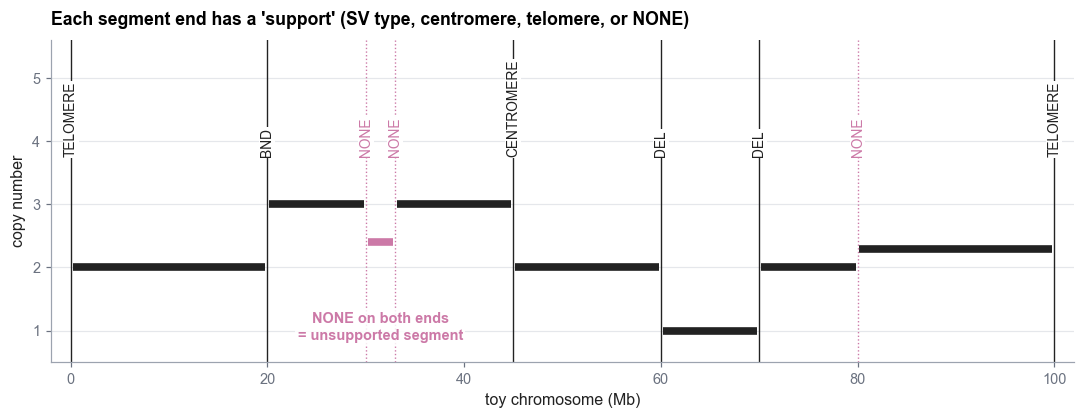

In [3]:
draw_support_track()

**그림에서 볼 것**: 검은 실선 경계는 근거가 있고, 자주색 점선 경계는 `NONE` 입니다. 자주색 구간(양쪽 다 `NONE`)만 근거 없는 구간으로 셉니다.

### QC 경고

**한 줄 정의**: `qc` 파일의 `QCStatus` 는 아래 규칙에 걸린 경고를 모두 적고, 하나도 없으면 `PASS` 입니다 [1].
이 노트북과 관련된 것은 두 개입니다: 근거 없는 구간이 220 개를 넘으면 `WARN_HIGH_COPY_NUMBER_NOISE`, purity 가 0.2 보다 낮으면 `WARN_LOW_PURITY`.
설명서는 앞의 경고가 "Mb 규모와 kb 규모의 GC 편향, 그리고 짧은 구간을 크게 증폭된 것처럼 보이게 하는 다른 잡음" 때문에 생길 수 있다고 적습니다 [1].

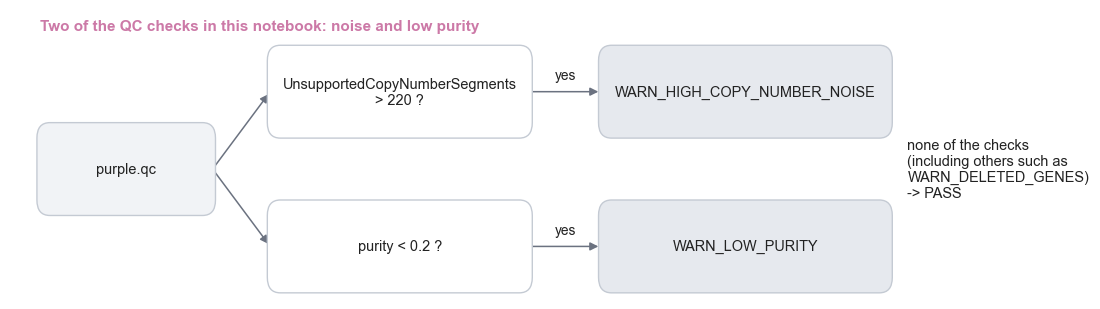

In [4]:
draw_qc_flow()

**그림에서 볼 것**: 두 경고는 따로 판정됩니다. B3 에서 본 것처럼 purity 0.2~0.3 시료는 `WARN_LOW_PURITY` 없이 `WARN_HIGH_COPY_NUMBER_NOISE` 만 붙기 쉽습니다.

**주의: SV 파일이 없으면 이 경고는 조용히 꺼집니다.** `UnsupportedCopyNumberSegments` 는 구간 가운데 SV 근거가 하나라도 있을 때만 셉니다. 하나도 없으면 0 으로 적습니다(`PurpleSummaryData.java`: `containsAnySvSupport ? … : 0` [2]).
SV VCF 없이 PURPLE 을 돌린 시료는 `UnsupportedCopyNumberSegments = 0`, 경고 없음으로 나오므로, 0 이 "잡음이 없다"는 뜻인지 "세지 않았다"는 뜻인지 먼저 확인하세요.

**주의: 이 노트북의 개수를 220 과 바로 비교하지 마세요.** 가짜 시료는 100 kb 칸과 단순한 구간 나누기·다듬기를 쓰므로(B3 원인 3 의 "실제 도구와 다른 점"), 근거 없는 구간 수의 크기가 실제와 다릅니다.
아래에서 `SIM_NOISY` 가 220 을 넘어 경고가 붙는 것은 "경향을 보여 주는 예"일 뿐입니다.

## 2. 가짜 시료를 PURPLE 형식으로 쓰기

B3 와 같은 종양으로 두 시료를 만듭니다.

- `SIM_CLEAN`: purity 0.6, 계통 잡음 0.02
- `SIM_NOISY`: purity 0.3, 계통 잡음 0.05, 시드 1 — B3 에서 두 배 해로 뒤집혔던 경우

아래 함수가 `purple_mini` 의 결과를 PURPLE 파일 형식으로 씁니다. 실제 파일보다 열이 적고(위 표의 열 위주), 값을 계산하지 않은 열(TMB, MSI 등)은 뺐습니다.
파일은 `data/sim/` 에 씁니다(git 에 올라가지 않음).

In [5]:
def run_mini_purple(purity, sys_sd, seed, depth=60):
    prof = pm.random_profile(seed=1)
    bins, bafs = pm.simulate(prof, purity, depth=depth, sys_sd=sys_sd, seed=seed)
    segs = pm.summarize(bins, bafs, pm.segment(bins, prof))
    fits = pm.fit(segs, depth)
    s = pm.summary(fits)
    fitted = pm.apply_fit(segs, s["purity"], s["normFactor"], depth)
    smoothed = pm.smooth(fitted, s["purity"])
    return dict(fits=fits, summary=s, segments=fitted, cnv=smoothed, depth=depth)


def to_bp(df):
    out = df.copy()
    out["start"] = out.start_bin * pm.BIN_KB * 1000 + 1
    out["end"] = out.end_bin * pm.BIN_KB * 1000
    return out


def polyclonal_proportion(cnv):
    off = (cnv.copyNumber - cnv.copyNumber.round()).abs() > 0.25
    return float((cnv.bafCount * off).sum() / max(cnv.bafCount.sum(), 1))


def wgd(cnv):
    g = cnv.groupby("chromosome").apply(lambda x: np.average(x.majorAlleleCopyNumber, weights=x.bafCount.clip(lower=1)),
                                        include_groups=False)
    return bool((g >= 1.5).sum() >= 11)


def write_purple(res, outdir, sample):
    os.makedirs(outdir, exist_ok=True)
    s, fits = res["summary"], res["fits"]
    cnv = to_bp(res["cnv"]).rename(columns={"tumorCopyNumber": "copyNumber", "tumorBAF": "baf",
                                            "start_support": "segmentStartSupport", "end_support": "segmentEndSupport"})
    cnv["method"] = "BAF_WEIGHTED"
    cnv_cols = ["chromosome", "start", "end", "copyNumber", "bafCount", "observedBAF", "baf", "segmentStartSupport",
                "segmentEndSupport", "method", "depthWindowCount", "minorAlleleCopyNumber", "majorAlleleCopyNumber"]
    cnv["baf"] = cnv.majorAlleleCopyNumber / cnv.copyNumber.where(cnv.copyNumber > 0)
    cnv[cnv_cols].to_csv(f"{outdir}/{sample}.purple.cnv.somatic.tsv", sep="\t", index=False, float_format="%.4f")

    seg = to_bp(res["segments"])
    seg["germlineStatus"], seg["observedNormalRatio"] = "DIPLOID", 1.0
    seg["support"] = seg.start_support
    seg_cols = ["chromosome", "start", "end", "germlineStatus", "bafCount", "observedBAF", "minorAlleleCopyNumber",
                "observedTumorRatio", "observedNormalRatio", "majorAlleleCopyNumber", "deviationPenalty",
                "tumorCopyNumber", "tumorBAF", "support", "depthWindowCount", "eventPenalty"]
    seg[seg_cols].to_csv(f"{outdir}/{sample}.purple.segment.tsv", sep="\t", index=False, float_format="%.4f")

    fits[["purity", "normFactor", "score", "diploidProportion", "ploidy"]].assign(somaticPenalty=0.0).to_csv(
        f"{outdir}/{sample}.purple.purity.range.tsv", sep="\t", index=False, float_format="%.4f")

    c = pm.candidates(fits)
    purity_row = dict(purity=s["purity"], normFactor=s["normFactor"], score=s["score"],
                      diploidProportion=s["diploidProportion"], ploidy=s["ploidy"], gender="FEMALE", status="NORMAL",
                      polyclonalProportion=polyclonal_proportion(cnv), minPurity=s["minPurity"], maxPurity=s["maxPurity"],
                      minPloidy=s["minPloidy"], maxPloidy=s["maxPloidy"],
                      minDiploidProportion=c.diploidProportion.min(), maxDiploidProportion=c.diploidProportion.max(),
                      somaticPenalty=0.0, wholeGenomeDuplication=str(wgd(cnv)).lower())
    pd.DataFrame([purity_row]).to_csv(f"{outdir}/{sample}.purple.purity.tsv", sep="\t", index=False, float_format="%.4f")

    unsupported = pm.unsupported_segments(res["cnv"])
    qc = [("QCStatus", pm.qc_status(unsupported, s["purity"])), ("Method", "NORMAL"),
          ("CopyNumberSegments", len(cnv)), ("UnsupportedCopyNumberSegments", unsupported),
          ("Purity", f"{s['purity']:.4f}"), ("AmberGender", "FEMALE"), ("CobaltGender", "FEMALE"),
          ("DeletedGenes", 0), ("Contamination", 0), ("GermlineAberrations", "NONE"), ("AmberMeanDepth", res["depth"])]
    with open(f"{outdir}/{sample}.purple.qc", "w") as fh:
        fh.write("".join(f"{k}\t{v}\n" for k, v in qc))


SIM_DIR = "data/sim"
sims = {"SIM_CLEAN": run_mini_purple(0.6, 0.02, seed=1), "SIM_NOISY": run_mini_purple(0.3, 0.05, seed=1)}
for name, res in sims.items():
    write_purple(res, f"{SIM_DIR}/{name}", name)
sorted(os.path.basename(f) for f in glob.glob(f"{SIM_DIR}/*/*"))

['SIM_CLEAN.purple.cnv.somatic.tsv',
 'SIM_CLEAN.purple.purity.range.tsv',
 'SIM_CLEAN.purple.purity.tsv',
 'SIM_CLEAN.purple.qc',
 'SIM_CLEAN.purple.segment.tsv',
 'SIM_NOISY.purple.cnv.somatic.tsv',
 'SIM_NOISY.purple.purity.range.tsv',
 'SIM_NOISY.purple.purity.tsv',
 'SIM_NOISY.purple.qc',
 'SIM_NOISY.purple.segment.tsv']

## 3. 실제 결과를 읽듯이 다시 읽기

이제부터는 파일만 봅니다. 실제 PURPLE 결과에도 그대로 쓸 수 있게, 시료 이름과 폴더만 받는 함수로 만듭니다.

In [6]:
def load_purple(sample_dir, sample):
    f = lambda ext: os.path.join(sample_dir, f"{sample}.purple.{ext}")
    qc = dict(line.rstrip("\n").split("\t", 1) for line in open(f("qc")) if "\t" in line)
    return dict(purity=pd.read_csv(f("purity.tsv"), sep="\t").iloc[0],
                range=pd.read_csv(f("purity.range.tsv"), sep="\t"),
                cnv=pd.read_csv(f("cnv.somatic.tsv"), sep="\t", dtype={"chromosome": str}),
                qc=qc)

loaded = {name: load_purple(f"{SIM_DIR}/{name}", name) for name in sims}
pd.DataFrame({n: d["purity"][["purity", "ploidy", "minPurity", "maxPurity", "minPloidy", "maxPloidy",
                              "diploidProportion", "polyclonalProportion", "wholeGenomeDuplication"]] for n, d in loaded.items()})

,SIM_CLEAN,SIM_NOISY
purity,0.61,0.18
ploidy,2.24,4.05
minPurity,0.59,0.16
maxPurity,0.62,0.34
minPloidy,2.2,2.14
maxPloidy,2.26,4.45
diploidProportion,0.4962,0.0048
polyclonalProportion,0.0,0.502
wholeGenomeDuplication,False,True


In [7]:
pd.DataFrame({n: d["qc"] for n, d in loaded.items()})

,SIM_CLEAN,SIM_NOISY
QCStatus,PASS,"WARN_HIGH_COPY_NUMBER_NOISE,WARN_LOW_PURITY"
Method,NORMAL,NORMAL
CopyNumberSegments,98,575
UnsupportedCopyNumberSegments,0,398
Purity,0.6100,0.1800
AmberGender,FEMALE,FEMALE
CobaltGender,FEMALE,FEMALE
DeletedGenes,0,0
Contamination,0,0
GermlineAberrations,NONE,NONE


`SIM_NOISY` 는 진짜 purity 0.3, ploidy 2.2 인 종양인데 파일에는 purity 0.18, ploidy 4.05 로 적혀 있습니다(이 노트북의 시뮬레이션 결과).
`wholeGenomeDuplication` 도 참으로 나옵니다. 파일만 보면 "purity 가 낮은 WGD 종양"으로 읽힙니다. 단서는 세 가지입니다.

- 후보 범위(`minPurity`~`maxPurity`)가 0.16~0.34 로 넓고, 진짜 purity 0.3 을 품고 있습니다.
- `polyclonalProportion` 이 0.5 입니다. 구간의 절반(BAF 가중)이 정수에서 0.25 넘게 벗어나 있습니다.
- QC 에 `WARN_HIGH_COPY_NUMBER_NOISE` 가 있습니다(장난감 개수라 220 과의 비교는 경향만 봅니다, 1절 주의). `WARN_LOW_PURITY` 도 붙었는데, 이것은 뒤집힌 답(0.18)이 0.2 보다 낮아서입니다. 진짜 purity 0.3 이면 붙지 않을 경고입니다.

### purity 범위 파일: 두 번째 골짜기 찾기

`purity.range.tsv` 에서 purity 마다 가장 낮은 점수만 골라 그리면(`FittedPurityRangeFile.bestFitPerPurity` 와 같은 일 [2]) B3 에서 본 점수 곡선이 나옵니다.

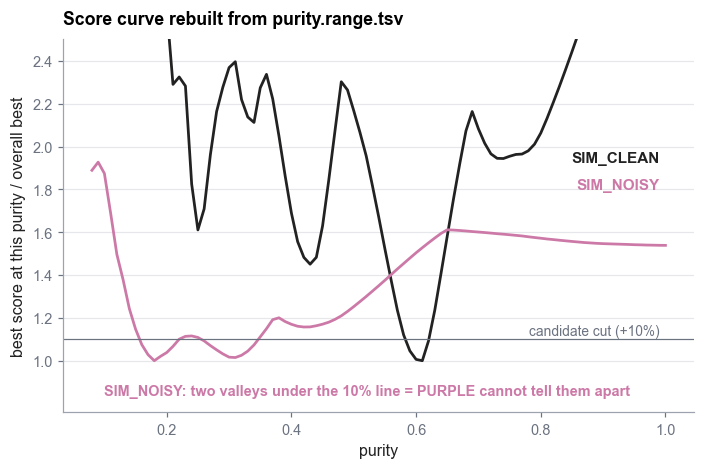

In [8]:
fig, ax = plt.subplots(figsize=(7.4, 4.4))
PAIR = [COL["ink"], COL["highlight"]]             # SIM_CLEAN 검정, SIM_NOISY 자주
for i, (name, d) in enumerate(loaded.items()):
    r = d["range"].sort_values("score").drop_duplicates("purity").sort_values("purity")
    ax.plot(r.purity, r.score / r.score.min(), color=PAIR[i], lw=1.8)
    note(ax, 0.99, 1.98 - 0.13 * i, name, ha="right", va="top", color=PAIR[i], fontsize=10, weight="semibold")
ax.axhline(1.1, color=COL["muted"], lw=0.8); note(ax, 0.99, 1.12, "candidate cut (+10%)", ha="right")
ax.set_ylim(0.76, 2.5); ax.set_yticks(np.arange(1.0, 2.6, 0.2)); ygrid(ax)
ax.set_xlabel("purity"); ax.set_ylabel("best score at this purity / overall best")
panel(ax, "", "Score curve rebuilt from purity.range.tsv")
callout(ax, 0.1, 0.86, "SIM_NOISY: two valleys under the 10% line = PURPLE cannot tell them apart", va="center", fontsize=9.5)
plt.show()

**그림에서 볼 것**: `SIM_NOISY`(자주색 선)는 0.18 과 0.31 두 곳에 10% 선 아래 골짜기가 있습니다. 하나는 PURPLE 이 고른 답, 하나는 그 "절반 ploidy" 해입니다(0.42 근처 골짜기는 10% 선 위).
`SIM_CLEAN`(검은 선)도 purity 0.25, 0.43 등에 골짜기가 있지만 모두 10% 선 위라, **10% 선 아래 골짜기는 하나**입니다(이 노트북의 시뮬레이션 결과).

## 4. 시료 하나를 확인하는 함수

B3 의 확인 목록을 함수로 만듭니다. 시료마다 한 줄을 돌려줍니다.

- `nrpcc`: `AmberMeanDepth` 와 purity, ploidy 로 계산한 종양 copy 당 read 수 [3]
- `purity_spread`: `maxPurity - minPurity`. PURPLE 은 0.15 이상이면 SNV 로 맞추기를 고려할 만큼 넓다고 봅니다 [1].
- `half_alt_ratio`: PURPLE 답이 두 배 해라고 할 때의 짝, 즉 purity $2p/(1+p)$·ploidy 절반 근처 추측의 최저 점수 ÷ 전체 최저 점수
- `double_alt_ratio`: 반대로 purity $p/(2-p)$·ploidy 두 배 근처 추측의 최저 점수 ÷ 전체 최저 점수
- 두 비율이 1.1 이하이면 그 짝도 후보 범위 안에 있다는 뜻입니다. PURPLE 이 둘을 못 가른 시료입니다.

In [9]:
def alt_ratio(rng, purity, ploidy, best):
    near = rng[(rng.purity - purity).abs() <= 0.02 + 1e-9]
    near = near[(near.ploidy / ploidy).between(0.8, 1.25)]
    return float(near.score.min() / best) if len(near) else np.nan


def check_sample(d):
    pu, rng, qc = d["purity"], d["range"], d["qc"]
    p, psi, best = float(pu.purity), float(pu.ploidy), float(rng.score.min())
    depth = float(qc.get("AmberMeanDepth", "nan"))
    row = dict(purity=p, ploidy=psi, nrpcc=pm.nrpcc(depth, p, psi), purity_spread=float(pu.maxPurity - pu.minPurity),
               unsupported=int(qc["UnsupportedCopyNumberSegments"]), qc=qc["QCStatus"],
               half_alt_ratio=alt_ratio(rng, 2 * p / (1 + p), psi / 2, best),
               double_alt_ratio=alt_ratio(rng, p / (2 - p), 2 * psi, best))
    row["ambiguous_doubling"] = bool(min(np.nan_to_num(row["half_alt_ratio"], nan=9),
                                         np.nan_to_num(row["double_alt_ratio"], nan=9)) <= 1.1)
    return row

checks = pd.DataFrame({n: check_sample(d) for n, d in loaded.items()}).T
checks

,purity,ploidy,nrpcc,purity_spread,unsupported,qc,half_alt_ratio,double_alt_ratio,ambiguous_doubling
SIM_CLEAN,0.61,2.24,17.051808,0.03,0,PASS,3.958215,1.450617,False
SIM_NOISY,0.18,4.05,4.558886,0.18,398,"WARN_HIGH_COPY_NUMBER_NOISE,WARN_LOW_PURITY",1.014778,1.906169,True


In [10]:
assert not checks.loc["SIM_CLEAN", "ambiguous_doubling"]
assert checks.loc["SIM_NOISY", "ambiguous_doubling"]
assert checks.loc["SIM_NOISY", "unsupported"] > checks.loc["SIM_CLEAN", "unsupported"]

`SIM_NOISY` 는 절반 ploidy 짝(purity 약 0.3, ploidy 약 2)의 점수가 최저와 거의 같아 `ambiguous_doubling` 이 참입니다. 바로 진짜 답입니다.
`SIM_CLEAN` 은 두 배 짝의 점수가 최저보다 한참 높아 거짓입니다.

이 확인은 "둘 중 어느 쪽이 맞다"를 말해 주지 않습니다. "PURPLE 이 둘을 못 갈랐다"를 알려 줄 뿐입니다.
어느 쪽인지는 B3 처럼 SNV VAF 봉우리, 다른 도구의 결과, 병리 purity 같은 다른 근거로 정합니다.

### 최종 CN 지도 그리기

`cnv.somatic.tsv` 만으로 CN 지도를 그립니다. 양쪽 끝 모두 근거가 `NONE` 인 구간은 자주색으로 칠합니다.

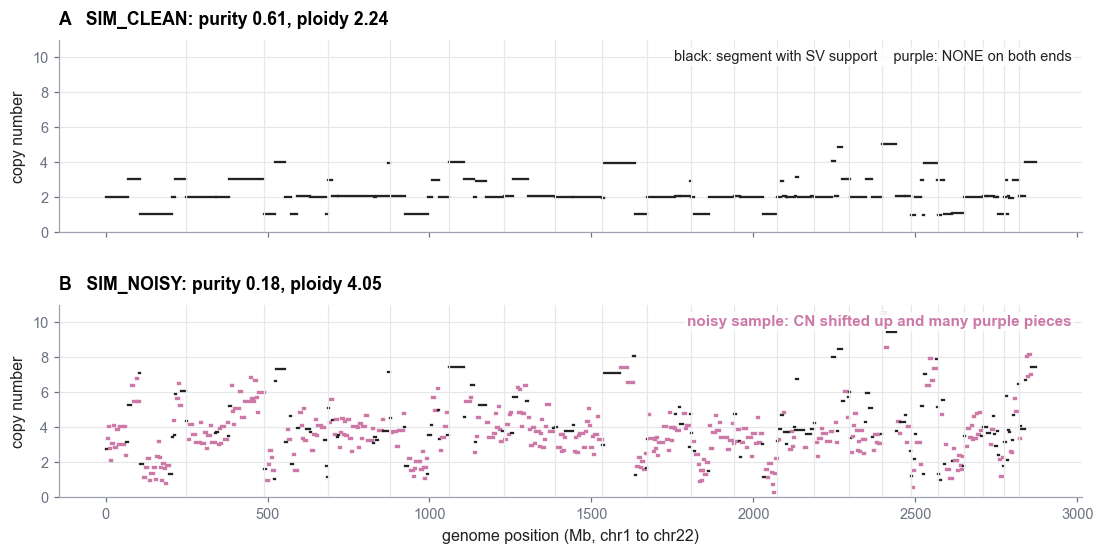

In [11]:
def plot_cnv(cnv, ax, title):
    order = sorted(cnv.chromosome.unique(), key=lambda c: int(c) if c.isdigit() else 99)
    sizes = cnv.groupby("chromosome").end.max().reindex(order)
    offset = dict(zip(order, np.concatenate([[0], np.cumsum(sizes.values)[:-1]])))
    for _, r in cnv.iterrows():
        o = offset[r.chromosome]
        bad = r.segmentStartSupport == "NONE" and r.segmentEndSupport == "NONE"
        ax.plot([(o + r.start) / 1e6, (o + r.end) / 1e6], [r.copyNumber] * 2, color=COL["highlight"] if bad else COL["ink"],
                lw=2.2 if bad else 1.5)
    for c in order[1:]:
        ax.axvline(offset[c] / 1e6, color=COL["grid"], lw=0.8)
    ax.set_ylim(0, 11); ax.set_ylabel("copy number"); ygrid(ax); panel(ax, "", title)

fig, axes = plt.subplots(2, 1, figsize=(12, 5.4), sharex=True, gridspec_kw={"hspace": 0.38})
for ax, letter, (name, d) in zip(axes, "AB", loaded.items()):
    plot_cnv(d["cnv"], ax, f"{letter}   {name}: purity {d['purity'].purity:.2f}, ploidy {d['purity'].ploidy:.2f}")
note(axes[0], 0.99, 0.95, "black: segment with SV support    purple: NONE on both ends", transform=axes[0].transAxes,
     ha="right", va="top", color=COL["ink"], fontsize=9.5, bbox=LABEL_BOX)
callout(axes[1], 0.99, 0.95, "noisy sample: CN shifted up and many purple pieces", transform=axes[1].transAxes, ha="right", va="top",
        bbox=LABEL_BOX)
axes[1].set_xlabel("genome position (Mb, chr1 to chr22)")
plt.show()

**그림에서 볼 것**: `SIM_NOISY` 의 CN 은 대부분 3~5 사이에 흩어져 있습니다. 진짜 CN(1~5)을 두 배 해로 옮긴 데다 잡음 구간(자주색)까지 더해져 있습니다.

## 5. (선택) 내 PURPLE 결과에 돌리기

환경 변수 `PURPLE_ROOT` 에 결과 폴더를 넣고 이 노트북을 돌리면, 그 아래의 모든 `*.purple.purity.tsv` 를 찾아 4절의 확인을 합니다.
폴더 구조가 깊으면 `PURPLE_GLOB` 으로 찾는 모양을 정할 수 있습니다(예: `*/*/purple/*.purple.purity.tsv`).

```bash
PURPLE_ROOT=/path/to/output PURPLE_GLOB='*/*/purple/*.purple.purity.tsv' \
  jupyter nbconvert --to notebook --execute lab04_outputs.ipynb --output data/lab04_outputs_mydata.ipynb
```

실제 결과를 넣고 돌린 노트북은 `data/` 에만 저장하세요. 공개 저장소에 올리지 않습니다. 아래 칸은 시료 이름을 출력하지 않고 모아 본 숫자만 보여 줍니다.

SV VCF 없이 돌린 시료는 근거 없는 구간 수가 0 으로 나오고 noise 경고도 붙지 않습니다(1절 주의). 코호트를 볼 때 이런 시료가 섞여 있지 않은지 먼저 확인하세요.

In [12]:
root = os.environ.get("PURPLE_ROOT")
if not root:
    print("PURPLE_ROOT 가 없어 이 절을 건너뜁니다.")
else:
    pattern = os.environ.get("PURPLE_GLOB", "**/*.purple.purity.tsv")
    files = sorted(glob.glob(os.path.join(root, pattern), recursive=True))
    rows = []
    for f in files:
        sample = os.path.basename(f).replace(".purple.purity.tsv", "")
        try:
            row = check_sample(load_purple(os.path.dirname(f), sample))
        except Exception as e:          # 파일이 빠진 시료는 건너뛴다
            continue
        rows.append(row)
    cohort = pd.DataFrame(rows)
    print(f"samples read: {len(cohort)} / {len(files)}")
    cohort["noise_warn"] = cohort.qc.str.contains("WARN_HIGH_COPY_NUMBER_NOISE")
    cohort["purity_bin"] = pd.cut(cohort.purity, [0, 0.2, 0.3, 0.4, 0.6, 1.0])
    display(cohort.groupby("purity_bin", observed=True).agg(
        n=("purity", "size"), noise_warn=("noise_warn", "mean"), ambiguous_doubling=("ambiguous_doubling", "mean"),
        median_unsupported=("unsupported", "median"), median_ploidy=("ploidy", "median")).round(2))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"wspace": 0.25})
    for flag, col, lab in [(False, COL["ink"], "clear fit"), (True, COL["highlight"], "doubling ambiguous")]:
        g = cohort[cohort.ambiguous_doubling == flag]
        axes[0].plot(g.purity, g.unsupported + 1, "o", ms=3, mew=0, alpha=0.6, color=col, label=lab)
        axes[1].plot(g.nrpcc, g.unsupported + 1, "o", ms=3, mew=0, alpha=0.6, color=col, label=lab)
    for ax, xl in zip(axes, ["purity", "NRPCC (reads per tumour chromosome copy)"]):
        ax.axhline(pm.MAX_UNSUPPORTED_SEGMENTS + 1, color=COL["muted"], lw=0.8, ls=(0, (4, 2)))
        ax.set_yscale("log"); ax.set_xlabel(xl); ax.set_ylabel("unsupported segments + 1"); ygrid(ax)
    axes[1].set_xscale("log"); axes[0].legend(fontsize=9.5, loc="lower right")
    panel(axes[0], "A", "Noise vs purity"); panel(axes[1], "B", "Noise vs NRPCC")
    note(axes[0], 0.99, pm.MAX_UNSUPPORTED_SEGMENTS * 1.15, "noise warning above 220", ha="right", va="bottom")
    plt.show()

    fig, ax = plt.subplots(figsize=(6.2, 4.6))
    ax.plot(cohort.purity, cohort.ploidy, "o", ms=3.5, mew=0, alpha=0.5, color=COL["ink"])
    ax.set_xlabel("purity"); ax.set_ylabel("ploidy"); ygrid(ax)
    panel(ax, "", "Purity vs ploidy of every sample")
    callout(ax, 0.03, 0.97, "low purity + high ploidy corner = check first", transform=ax.transAxes, va="top", fontsize=9.5)
    plt.show()

PURPLE_ROOT 가 없어 이 절을 건너뜁니다.


실제 결과에서 볼 점:

- purity 가 낮은 구간일수록 CN noise 경고 비율과 근거 없는 구간 수가 늘어나는가 (B3 원인 3)
- `ambiguous_doubling` 이 참인 시료가 낮은 purity 에 몰려 있는가, 그 시료들의 ploidy 가 3.5 를 넘는가 (B3 원인 4)
- 위 두 그림 중 purity 와 NRPCC 어느 쪽이 근거 없는 구간 수를 더 잘 가르는가 (B3 원인 1·2)

`ambiguous_doubling` 이 참이고 ploidy 가 높은 시료는 SNV VAF 봉우리나 다른 도구의 purity 와 맞춰 보는 것이 좋습니다.

## 연습 문제

1. PURPLE 결과가 purity 0.25, ploidy 4.2, AmberMeanDepth 80 입니다. NRPCC 는 얼마입니까?
2. 같은 시료에서 "절반 ploidy" 짝의 purity 는 얼마입니까?
3. `purity.range.tsv` 에서 purity 마다 최저 점수 하나만 남기는 pandas 한 줄을 써 보세요.
4. 1절의 장난감 염색체에서 30~33 Mb 구간의 끝 근거가 `NONE` 대신 `DUP` 이면 근거 없는 구간은 몇 개입니까?

<details><summary>정답 보기</summary>

1. $80 \times 0.25 / (0.25 \times 4.2 + 2 \times 0.75) = 20 / 2.55 \approx 7.8$.
2. $2 \times 0.25 / 1.25 = 0.4$, ploidy 약 2.1.
3. `rng.sort_values("score").drop_duplicates("purity").sort_values("purity")`
4. 0 개. 한쪽 끝에라도 근거가 있으면 세지 않습니다.

</details>

In [13]:
assert np.isclose(pm.nrpcc(80, 0.25, 4.2), 7.84, atol=0.01)
assert np.isclose(2 * 0.25 / 1.25, 0.4)

## 정리

- 최종 답은 `purity.tsv` 에, 그 답이 얼마나 확실한지는 `minPurity`~`maxPurity` 와 `purity.range.tsv` 에 있습니다.
- CN noise 경고의 근거는 `purple.qc` 의 `UnsupportedCopyNumberSegments` 이고, 어떤 구간이 그것인지는 `cnv.somatic.tsv` 의 근거 열(`NONE`)로 찾습니다.
- 두 배 해 짝의 점수를 `purity.range.tsv` 에서 직접 찾아보면, PURPLE 이 두 해를 못 가른 시료를 골라낼 수 있습니다.
- 그런 시료의 최종 판단은 SNV VAF 같은 독립 근거로 합니다.

## 출처

모두 2026-11-13 에 직접 열어 확인했습니다.

1. **PURPLE README**, hmftools 태그 `purple-v4.1`. https://github.com/hartwigmedical/hmftools/blob/purple-v4.1/purple/README.md
   — 이 노트북에서: Output 절의 파일과 열 설명(purity file, purity range file, qc file, copy number file 의 support 값), QC 규칙(`WARN_HIGH_COPY_NUMBER_NOISE` > 220 과 그 원인 문장, `WARN_LOW_PURITY` < 20%), 후보 purity 범위 0.15 조건, WGD 정의 문장.
2. **PURPLE·hmf-common 소스**, 태그 `purple-v4.1`. https://github.com/hartwigmedical/hmftools/tree/purple-v4.1
   — `hmf-common/.../purple/PurityContextFile.java`(purity.tsv 열, `status` 에 맞추기 방식), `PurpleQCFile.java`(qc 열), `FittedPurityRangeFile.java`(`bestFitPerPurity`), `purple/.../PurpleApplication.java`(range 파일에 `AllFits` 를 씀), `purple/.../PurpleSummaryData.java`(SV 근거가 하나도 없으면 근거 없는 구간 수를 0 으로 둠), `purple/.../fitting/WholeGenomeDuplication.java`(1.5 이상, 11 개 이상).
3. **Dentro SC, et al.** (2021) Characterizing genetic intra-tumor heterogeneity across 2,658 human cancer genomes. *Cell* 184:2239–2254. https://doi.org/10.1016/j.cell.2021.03.009
   — NRPCC 정의.

`SIM_CLEAN`·`SIM_NOISY` 의 모든 값은 **이 노트북의 시뮬레이션 결과**입니다. 5절은 `PURPLE_ROOT` 를 준 사람의 데이터로만 돌고, 이 저장소의 노트북에는 그 결과가 들어 있지 않습니다.